In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()

# If your notebook starts in the notebooks folder,
# use the project root one level above it.
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
CLEANED_DIR = PROJECT_ROOT / "data" / "cleaned"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

print("Project root:", PROJECT_ROOT.resolve())
print("Raw directory exists:", RAW_DIR.exists())
print("Cleaned directory exists:", CLEANED_DIR.exists())

Project root: D:\NILM Flock energy assignment
Raw directory exists: True
Cleaned directory exists: True


In [2]:
def inventory_files(folder):
    records = []

    for path in folder.rglob("*"):
        if path.is_file():
            records.append({
                "filename": path.name,
                "extension": path.suffix.lower(),
                "size_mb": round(path.stat().st_size / (1024**2), 2),
                "path": str(path.resolve())
            })

    return pd.DataFrame(records)


raw_inventory = inventory_files(RAW_DIR)
cleaned_inventory = inventory_files(CLEANED_DIR)

print("RAW FILES")
display(raw_inventory)

print("CLEANED FILES")
display(cleaned_inventory)

RAW FILES


,filename,extension,size_mb,path
0,RAW_House10_Part1.csv,.csv,217.29,D:\NILM Flock energy assignment\data\raw\RAW_H...
1,RAW_House10_Part2.csv,.csv,223.99,D:\NILM Flock energy assignment\data\raw\RAW_H...
2,RAW_House11_Part1.csv,.csv,76.91,D:\NILM Flock energy assignment\data\raw\RAW_H...
3,RAW_House11_Part2.csv,.csv,204.46,D:\NILM Flock energy assignment\data\raw\RAW_H...
4,RAW_House12_Part1.csv,.csv,167.05,D:\NILM Flock energy assignment\data\raw\RAW_H...
5,RAW_House12_Part2.csv,.csv,228.16,D:\NILM Flock energy assignment\data\raw\RAW_H...
6,RAW_House1_Part1.csv,.csv,232.27,D:\NILM Flock energy assignment\data\raw\RAW_H...
7,RAW_House1_Part2.csv,.csv,228.55,D:\NILM Flock energy assignment\data\raw\RAW_H...
8,RAW_House2_Part1.csv,.csv,184.58,D:\NILM Flock energy assignment\data\raw\RAW_H...
9,RAW_House2_Part2.csv,.csv,197.63,D:\NILM Flock energy assignment\data\raw\RAW_H...


CLEANED FILES


,filename,extension,size_mb,path
0,CLEAN_House1.csv,.csv,382.27,D:\NILM Flock energy assignment\data\cleaned\C...
1,CLEAN_House10.csv,.csv,380.28,D:\NILM Flock energy assignment\data\cleaned\C...
2,CLEAN_House11.csv,.csv,243.98,D:\NILM Flock energy assignment\data\cleaned\C...
3,CLEAN_House12.csv,.csv,319.49,D:\NILM Flock energy assignment\data\cleaned\C...
4,CLEAN_House13.csv,.csv,263.71,D:\NILM Flock energy assignment\data\cleaned\C...
5,CLEAN_House15.csv,.csv,336.79,D:\NILM Flock energy assignment\data\cleaned\C...
6,CLEAN_House16.csv,.csv,318.47,D:\NILM Flock energy assignment\data\cleaned\C...
7,CLEAN_House17.csv,.csv,303.20,D:\NILM Flock energy assignment\data\cleaned\C...
8,CLEAN_House18.csv,.csv,287.57,D:\NILM Flock energy assignment\data\cleaned\C...
9,CLEAN_House19.csv,.csv,305.84,D:\NILM Flock energy assignment\data\cleaned\C...


In [3]:
def find_house1_candidates(inventory):
    if inventory.empty:
        return inventory

    mask = inventory["filename"].str.contains(
        r"house[\s_-]*0?1(?:\D|$)",
        case=False,
        regex=True,
        na=False
    )

    return inventory.loc[mask].copy()


raw_house1 = find_house1_candidates(raw_inventory)
cleaned_house1 = find_house1_candidates(cleaned_inventory)

display(raw_house1)
display(cleaned_house1)

,filename,extension,size_mb,path
6,RAW_House1_Part1.csv,.csv,232.27,D:\NILM Flock energy assignment\data\raw\RAW_H...
7,RAW_House1_Part2.csv,.csv,228.55,D:\NILM Flock energy assignment\data\raw\RAW_H...


,filename,extension,size_mb,path
0,CLEAN_House1.csv,.csv,382.27,D:\NILM Flock energy assignment\data\cleaned\C...


In [4]:
import csv

def inspect_csv(path, rows=5):
    path = Path(path)

    print(f"\nFile: {path.name}")
    print(f"Size: {path.stat().st_size / (1024**2):.2f} MB")

    # Read a small sample; do not load the whole dataset.
    sample = pd.read_csv(
        path,
        nrows=rows,
        encoding="utf-8-sig",
        on_bad_lines="warn"
    )

    print("\nColumns:")
    print(sample.columns.tolist())

    print("\nData types:")
    print(sample.dtypes)

    print("\nSample:")
    display(sample)

    return sample

In [11]:
# Build the path from the project-root directory defined in cell 1.
RAW_HOUSE1_PATH = RAW_DIR / "RAW_House1_Part1.csv"

raw_sample = inspect_csv(RAW_HOUSE1_PATH)


File: RAW_House1_Part1.csv
Size: 232.27 MB

Columns:
['Time', 'Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9']

Data types:
Time            str
Unix          int64
Aggregate     int64
Appliance1    int64
Appliance2    int64
Appliance3    int64
Appliance4    int64
Appliance5    int64
Appliance6    int64
Appliance7    int64
Appliance8    int64
Appliance9    int64
dtype: object

Sample:


,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2013-10-09 14:06:17,1381327577,523,74,0,69,0,0,0,0,0,1
1,2013-10-09 14:06:31,1381327591,526,75,0,69,0,0,0,0,0,1
2,2013-10-09 14:06:46,1381327606,540,74,0,68,0,0,0,0,0,1
3,2013-10-09 14:07:01,1381327621,532,74,0,68,0,0,0,0,0,1
4,2013-10-09 14:07:15,1381327634,540,74,0,69,0,0,0,0,0,1


In [12]:
# Find all House 1 raw files, including Part1, Part2, etc.
house1_parts = sorted(
    [
        p for p in RAW_DIR.rglob("*.csv")
        if p.name.lower().startswith("raw_house1_")
    ],
    key=lambda p: p.name
)

print(f"Found {len(house1_parts)} raw House 1 files:")

for p in house1_parts:
    print(f"{p.name:30} {p.stat().st_size / (1024**2):8.2f} MB")

Found 2 raw House 1 files:
RAW_House1_Part1.csv             232.27 MB
RAW_House1_Part2.csv             228.55 MB


In [13]:
clean_house1_path = CLEANED_DIR / "CLEAN_House1.csv"

if not clean_house1_path.exists():
    raise FileNotFoundError(
        f"Could not find {clean_house1_path}. "
        "Check the cleaned directory inventory."
    )

clean_sample = pd.read_csv(
    clean_house1_path,
    nrows=5,
    encoding="utf-8-sig"
)

print("Columns:")
print(clean_sample.columns.tolist())

print("\nData types:")
print(clean_sample.dtypes)

print("\nFirst five rows:")
display(clean_sample)

print("\nFile size (MB):",
      round(clean_house1_path.stat().st_size / (1024**2), 2))

Columns:
['Time', 'Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9', 'Issues']

Data types:
Time            str
Unix          int64
Aggregate     int64
Appliance1    int64
Appliance2    int64
Appliance3    int64
Appliance4    int64
Appliance5    int64
Appliance6    int64
Appliance7    int64
Appliance8    int64
Appliance9    int64
Issues        int64
dtype: object

First five rows:


,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9,Issues
0,2013-10-09 13:06:17,1381323977,523,74,0,69,0,0,0,0,0,1,0
1,2013-10-09 13:06:31,1381323991,526,75,0,69,0,0,0,0,0,1,0
2,2013-10-09 13:06:46,1381324006,540,74,0,68,0,0,0,0,0,1,0
3,2013-10-09 13:07:01,1381324021,532,74,0,68,0,0,0,0,0,1,0
4,2013-10-09 13:07:15,1381324035,540,74,0,69,0,0,0,0,0,1,0



File size (MB): 382.27


In [14]:
from collections import Counter

def scan_raw_file(path, chunksize=250_000):
    rows = 0
    min_unix = None
    max_unix = None
    missing_counts = Counter()
    interval_counts = Counter()
    previous_unix = None
    nonpositive_intervals = 0

    for chunk in pd.read_csv(
        path,
        usecols=["Unix", "Aggregate"],
        chunksize=chunksize
    ):
        rows += len(chunk)

        missing_counts.update(chunk.isna().sum().to_dict())

        unix = pd.to_numeric(chunk["Unix"], errors="coerce")
        valid = unix.dropna()

        if not valid.empty:
            chunk_min = valid.min()
            chunk_max = valid.max()

            min_unix = (
                chunk_min if min_unix is None
                else min(min_unix, chunk_min)
            )
            max_unix = (
                chunk_max if max_unix is None
                else max(max_unix, chunk_max)
            )

            # Inspect sequential sampling intervals, including
            # the boundary between consecutive chunks.
            values = valid.to_numpy()

            if previous_unix is not None and len(values):
                interval_counts[int(values[0] - previous_unix)] += 1

            if len(values) > 1:
                diffs = np.diff(values)
                interval_counts.update(diffs.astype(int).tolist())
                nonpositive_intervals += int((diffs <= 0).sum())

            if len(values):
                previous_unix = values[-1]

    return {
        "file": path.name,
        "rows": rows,
        "first_unix_min": min_unix,
        "last_unix_max": max_unix,
        "missing_unix": missing_counts["Unix"],
        "missing_aggregate": missing_counts["Aggregate"],
        "nonpositive_intervals": nonpositive_intervals,
        "common_intervals_seconds": interval_counts.most_common(8),
    }


raw_scan = pd.DataFrame([
    scan_raw_file(path)
    for path in house1_parts
])

display(raw_scan)

,file,rows,first_unix_min,last_unix_max,missing_unix,missing_aggregate,nonpositive_intervals,common_intervals_seconds
0,RAW_House1_Part1.csv,4377877,1381327577,1412126827,0,0,1003948,"[(0, 1003950), (2, 971607), (13, 609775), (15,..."
1,RAW_House1_Part2.csv,4140886,1403906269,1436529392,0,188973,14755,"[(7, 1754601), (6, 924521), (8, 887002), (9, 3..."


In [15]:
def inspect_part_boundaries(paths):
    records = []

    for path in paths:
        sample = pd.read_csv(
            path,
            usecols=["Unix"],
            dtype={"Unix": "Int64"},
            encoding="utf-8-sig"
        )

        unix = sample["Unix"].dropna()

        records.append({
            "file": path.name,
            "rows": len(sample),
            "min_unix": unix.min() if len(unix) else None,
            "max_unix": unix.max() if len(unix) else None,
        })

    return pd.DataFrame(records)


# Note: this reads only the Unix column, but still scans each file.
# Run after confirming the files in Cell 5.
boundaries = inspect_part_boundaries(house1_parts)
display(boundaries)

,file,rows,min_unix,max_unix
0,RAW_House1_Part1.csv,4377877,1381327577,1412126827
1,RAW_House1_Part2.csv,4140886,1403906269,1436529392


In [16]:
def diagnose_timestamps(path, chunksize=250_000):
    rows = 0
    first_values = []
    last_values = []
    previous = None

    non_increasing = 0
    duplicate_adjacent = 0
    negative_intervals = 0
    interval_counts = Counter()

    for chunk in pd.read_csv(
        path,
        usecols=["Unix"],
        chunksize=chunksize
    ):
        unix = pd.to_numeric(chunk["Unix"], errors="coerce")
        unix = unix.dropna().to_numpy(dtype=np.int64)

        if len(unix) == 0:
            continue

        rows += len(unix)

        if len(first_values) < 5:
            first_values.extend(unix[:5 - len(first_values)].tolist())

        last_values.extend(unix.tolist())
        last_values = last_values[-5:]

        # Include the boundary between consecutive chunks.
        if previous is not None:
            delta = int(unix[0] - previous)
            interval_counts[delta] += 1

            if delta <= 0:
                non_increasing += 1
            if delta == 0:
                duplicate_adjacent += 1
            if delta < 0:
                negative_intervals += 1

        if len(unix) > 1:
            delta = np.diff(unix)
            interval_counts.update(delta.tolist())

            non_increasing += int((delta <= 0).sum())
            duplicate_adjacent += int((delta == 0).sum())
            negative_intervals += int((delta < 0).sum())

        previous = int(unix[-1])

    return {
        "file": path.name,
        "valid_timestamp_rows": rows,
        "first_rows_unix": first_values,
        "last_rows_unix": last_values,
        "non_increasing_intervals": non_increasing,
        "adjacent_duplicates": duplicate_adjacent,
        "negative_intervals": negative_intervals,
        "most_common_intervals": interval_counts.most_common(10),
    }


for path in house1_parts:
    print(diagnose_timestamps(path))

{'file': 'RAW_House1_Part1.csv', 'valid_timestamp_rows': 4377877, 'first_rows_unix': [1381327577, 1381327591, 1381327606, 1381327621, 1381327634], 'last_rows_unix': [1412126797, 1412126810, 1412126812, 1412126827, 1412126827], 'non_increasing_intervals': 1003951, 'adjacent_duplicates': 1003950, 'negative_intervals': 1, 'most_common_intervals': [(0, 1003950), (2, 971607), (13, 609775), (15, 420480), (11, 306554), (4, 270295), (3, 153223), (9, 116389), (1, 108813), (5, 72616)]}
{'file': 'RAW_House1_Part2.csv', 'valid_timestamp_rows': 4140886, 'first_rows_unix': [1403906269, 1403906271, 1403906278, 1403906286, 1403906293], 'last_rows_unix': [1436529364, 1436529371, 1436529377, 1436529384, 1436529392], 'non_increasing_intervals': 14755, 'adjacent_duplicates': 14755, 'negative_intervals': 0, 'most_common_intervals': [(7, 1754601), (6, 924521), (8, 887002), (9, 324367), (5, 181660), (2, 16350), (0, 14755), (13, 11338), (11, 5924), (10, 3603)]}


In [17]:
part_ranges = []

for path in house1_parts:
    stats = scan_raw_file(path)

    part_ranges.append({
        "file": path.name,
        "min_unix": stats["first_unix_min"],
        "max_unix": stats["last_unix_max"],
    })

ranges_df = pd.DataFrame(part_ranges)
display(ranges_df)

if len(ranges_df) >= 2:
    a = ranges_df.iloc[0]
    b = ranges_df.iloc[1]

    overlap_start = max(a["min_unix"], b["min_unix"])
    overlap_end = min(a["max_unix"], b["max_unix"])

    if overlap_start <= overlap_end:
        print("Timestamp ranges overlap.")
        print("Overlap starts:", pd.to_datetime(
            overlap_start, unit="s", utc=True
        ))
        print("Overlap ends:", pd.to_datetime(
            overlap_end, unit="s", utc=True
        ))
    else:
        print("Timestamp ranges do not overlap.")

,file,min_unix,max_unix
0,RAW_House1_Part1.csv,1381327577,1412126827
1,RAW_House1_Part2.csv,1403906269,1436529392


Timestamp ranges overlap.
Overlap starts: 2014-06-27 21:57:49+00:00
Overlap ends: 2014-10-01 01:27:07+00:00


In [18]:
OVERLAP_START = 1403906269
OVERLAP_END = 1412126827

def summarize_overlap(path, chunksize=250_000):
    summaries = []

    for chunk in pd.read_csv(
        path,
        usecols=["Unix", "Aggregate"],
        chunksize=chunksize
    ):
        chunk = chunk.loc[
            chunk["Unix"].between(OVERLAP_START, OVERLAP_END)
        ].copy()

        if chunk.empty:
            continue

        summary = (
            chunk.groupby("Unix", sort=False)
            .agg(
                row_count=("Aggregate", "size"),
                aggregate_min=("Aggregate", "min"),
                aggregate_max=("Aggregate", "max"),
            )
            .reset_index()
        )

        summaries.append(summary)

    if not summaries:
        return pd.DataFrame(columns=[
            "Unix", "row_count", "aggregate_min", "aggregate_max"
        ])

    # Merge groups that may have appeared in different chunks.
    result = pd.concat(summaries, ignore_index=True)

    result = (
        result.groupby("Unix", as_index=False)
        .agg(
            row_count=("row_count", "sum"),
            aggregate_min=("aggregate_min", "min"),
            aggregate_max=("aggregate_max", "max"),
        )
    )

    return result


part1_overlap = summarize_overlap(house1_parts[0])
part2_overlap = summarize_overlap(house1_parts[1])

print("Part 1 overlap rows after grouping:", len(part1_overlap))
print("Part 2 overlap rows after grouping:", len(part2_overlap))

Part 1 overlap rows after grouping: 835888
Part 2 overlap rows after grouping: 942783


In [19]:
comparison = part1_overlap.merge(
    part2_overlap,
    on="Unix",
    how="outer",
    suffixes=("_part1", "_part2"),
    indicator=True
)

print("Timestamp comparison:")
display(comparison["_merge"].value_counts())

matched = comparison.loc[comparison["_merge"] == "both"].copy()

print("Shared unique timestamps:", len(matched))

matched["aggregate_matches"] = (
    matched["aggregate_min_part1"].eq(matched["aggregate_min_part2"])
    & matched["aggregate_max_part1"].eq(matched["aggregate_max_part2"])
)

print("\nAggregate comparison:")
display(matched["aggregate_matches"].value_counts())

print("\nTimestamps with different aggregate ranges:")
display(
    matched.loc[
        ~matched["aggregate_matches"]
    ].head(10)
)

Timestamp comparison:


_merge
right_only    750894
left_only     643999
both          191889
Name: count, dtype: int64

Shared unique timestamps: 191889

Aggregate comparison:


aggregate_matches
False    154901
True      36988
Name: count, dtype: int64


Timestamps with different aggregate ranges:


,Unix,row_count_part1,aggregate_min_part1,aggregate_max_part1,row_count_part2,aggregate_min_part2,aggregate_max_part2,_merge,aggregate_matches
27,1403906364,1.0,324.0,324.0,1.0,319.0,319.0,both,False
31,1403906380,2.0,322.0,322.0,1.0,320.0,320.0,both,False
47,1403906443,1.0,323.0,323.0,1.0,321.0,321.0,both,False
52,1403906460,1.0,318.0,318.0,1.0,NaN,NaN,both,False
55,1403906475,1.0,325.0,325.0,1.0,321.0,321.0,both,False
59,1403906490,1.0,323.0,323.0,1.0,322.0,322.0,both,False
78,1403906562,1.0,372.0,372.0,1.0,371.0,371.0,both,False
82,1403906577,1.0,364.0,364.0,1.0,372.0,372.0,both,False
98,1403906649,1.0,359.0,359.0,1.0,360.0,360.0,both,False
101,1403906664,2.0,358.0,363.0,1.0,360.0,360.0,both,False


In [20]:
def duplicate_summary(df, name):
    duplicate_timestamps = df["row_count"] > 1

    print(f"\n{name}")
    print("Unique timestamps:", len(df))
    print("Timestamps with repeated rows:", int(duplicate_timestamps.sum()))
    print("Extra rows beyond one per timestamp:",
          int((df["row_count"] - 1).clip(lower=0).sum()))

    conflicting_aggregate = (
        df["aggregate_min"] != df["aggregate_max"]
    )

    print("Timestamps with conflicting aggregate readings:",
          int(conflicting_aggregate.sum()))


duplicate_summary(part1_overlap, "Part 1 — overlapping interval")
duplicate_summary(part2_overlap, "Part 2 — overlapping interval")


Part 1 — overlapping interval
Unique timestamps: 835888
Timestamps with repeated rows: 341368
Extra rows beyond one per timestamp: 421977
Timestamps with conflicting aggregate readings: 30374

Part 2 — overlapping interval
Unique timestamps: 942783
Timestamps with repeated rows: 2620
Extra rows beyond one per timestamp: 2620
Timestamps with conflicting aggregate readings: 52930


In [21]:
clean_path = CLEANED_DIR / "CLEAN_House1.csv"

print("Columns:", clean_sample.columns.tolist())
print("Rows in sample:", len(clean_sample))

def scan_cleaned_file(path, chunksize=250_000):
    total_rows = 0
    missing_counts = Counter()
    unix_min = None
    unix_max = None
    previous_unix = None
    non_increasing = 0
    duplicate_intervals = 0

    for chunk in pd.read_csv(
        path,
        chunksize=chunksize,
        encoding="utf-8-sig"
    ):
        total_rows += len(chunk)
        missing_counts.update(chunk.isna().sum().to_dict())

        if "Unix" not in chunk.columns:
            raise ValueError("No Unix column found in cleaned dataset.")

        unix = pd.to_numeric(chunk["Unix"], errors="coerce")
        valid = unix.dropna().to_numpy(dtype=np.int64)

        if len(valid) == 0:
            continue

        chunk_min, chunk_max = valid.min(), valid.max()
        unix_min = chunk_min if unix_min is None else min(unix_min, chunk_min)
        unix_max = chunk_max if unix_max is None else max(unix_max, chunk_max)

        diffs = np.diff(valid)

        if previous_unix is not None:
            boundary_diff = int(valid[0] - previous_unix)
            non_increasing += int(boundary_diff <= 0)
            duplicate_intervals += int(boundary_diff == 0)

        non_increasing += int((diffs <= 0).sum())
        duplicate_intervals += int((diffs == 0).sum())

        previous_unix = int(valid[-1])

    return {
        "rows": total_rows,
        "missing_values": dict(missing_counts),
        "min_unix": unix_min,
        "max_unix": unix_max,
        "non_increasing_intervals": non_increasing,
        "duplicate_intervals": duplicate_intervals,
    }


clean_stats = scan_cleaned_file(clean_path)

print(clean_stats)

Columns: ['Time', 'Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9', 'Issues']
Rows in sample: 5
{'rows': 6960008, 'missing_values': {'Time': 0, 'Unix': 0, 'Aggregate': 0, 'Appliance1': 0, 'Appliance2': 0, 'Appliance3': 0, 'Appliance4': 0, 'Appliance5': 0, 'Appliance6': 0, 'Appliance7': 0, 'Appliance8': 0, 'Appliance9': 0, 'Issues': 0}, 'min_unix': np.int64(1381323977), 'max_unix': np.int64(1436529392), 'non_increasing_intervals': 0, 'duplicate_intervals': 0}


In [22]:
time_check = pd.read_csv(
    clean_path,
    usecols=["Time", "Unix"],
    nrows=10,
    encoding="utf-8-sig"
)

time_check["Time_parsed"] = pd.to_datetime(
    time_check["Time"],
    errors="coerce"
)

time_check["Unix_UTC"] = pd.to_datetime(
    time_check["Unix"],
    unit="s",
    utc=True,
    errors="coerce"
)

display(time_check)

,Time,Unix,Time_parsed,Unix_UTC
0,2013-10-09 13:06:17,1381323977,2013-10-09 13:06:17,2013-10-09 13:06:17+00:00
1,2013-10-09 13:06:31,1381323991,2013-10-09 13:06:31,2013-10-09 13:06:31+00:00
2,2013-10-09 13:06:46,1381324006,2013-10-09 13:06:46,2013-10-09 13:06:46+00:00
3,2013-10-09 13:07:01,1381324021,2013-10-09 13:07:01,2013-10-09 13:07:01+00:00
4,2013-10-09 13:07:15,1381324035,2013-10-09 13:07:15,2013-10-09 13:07:15+00:00
5,2013-10-09 13:07:18,1381324038,2013-10-09 13:07:18,2013-10-09 13:07:18+00:00
6,2013-10-09 13:07:30,1381324050,2013-10-09 13:07:30,2013-10-09 13:07:30+00:00
7,2013-10-09 13:07:32,1381324052,2013-10-09 13:07:32,2013-10-09 13:07:32+00:00
8,2013-10-09 13:07:44,1381324064,2013-10-09 13:07:44,2013-10-09 13:07:44+00:00
9,2013-10-09 13:07:47,1381324067,2013-10-09 13:07:47,2013-10-09 13:07:47+00:00


In [23]:
OVERLAP_START = 1403906269
OVERLAP_END = 1412126827

def load_actual_overlap(path, chunksize=250_000):
    selected_columns = [
        "Time", "Unix", "Aggregate", "Appliance4", "Appliance5"
    ]
    overlap_chunks = []

    for chunk in pd.read_csv(
        path,
        usecols=selected_columns,
        chunksize=chunksize
    ):
        chunk["Unix"] = pd.to_numeric(
            chunk["Unix"], errors="coerce"
        )

        mask = chunk["Unix"].between(
            OVERLAP_START, OVERLAP_END
        )

        if mask.any():
            overlap_chunks.append(chunk.loc[mask].copy())

    if not overlap_chunks:
        return pd.DataFrame(columns=selected_columns)

    return pd.concat(overlap_chunks, ignore_index=True)


overlap_part1 = load_actual_overlap(house1_parts[0])
overlap_part2 = load_actual_overlap(house1_parts[1])

print("Part 1 actual overlap rows:", len(overlap_part1))
print("Part 2 actual overlap rows:", len(overlap_part2))

display(overlap_part1.head())
display(overlap_part2.head())

Part 1 actual overlap rows: 1257865
Part 2 actual overlap rows: 945403


,Time,Unix,Aggregate,Appliance4,Appliance5
0,2014-06-27 21:57:54,1403906273,322,0,0
1,2014-06-27 21:57:56,1403906275,322,0,0
2,2014-06-27 21:58:09,1403906288,323,0,0
3,2014-06-27 21:58:11,1403906291,322,0,0
4,2014-06-27 21:58:24,1403906304,320,0,0


,Time,Unix,Aggregate,Appliance4,Appliance5
0,2014-06-27 21:57:50,1403906269,322.0,0.0,0.0
1,2014-06-27 21:57:51,1403906271,NaN,NaN,NaN
2,2014-06-27 21:57:58,1403906278,329.0,NaN,0.0
3,2014-06-27 21:58:06,1403906286,322.0,NaN,NaN
4,2014-06-27 21:58:14,1403906293,320.0,NaN,0.0


In [24]:
def overlap_quality_report(df, name):
    repeated = df["Unix"].duplicated(keep=False)

    aggregate_range = (
        df.groupby("Unix")["Aggregate"]
        .agg(["count", "min", "max"])
    )

    print(f"\n{name}")
    print("Total rows:", len(df))
    print("Unique timestamps:", df["Unix"].nunique())
    print("Rows at repeated timestamps:", int(repeated.sum()))
    print(
        "Timestamps with conflicting aggregate readings:",
        int((aggregate_range["min"] != aggregate_range["max"]).sum())
    )
    print(
        "Missing aggregate readings:",
        int(df["Aggregate"].isna().sum())
    )
    print(
        "Missing Appliance4 readings:",
        int(df["Appliance4"].isna().sum())
    )
    print(
        "Missing Appliance5 readings:",
        int(df["Appliance5"].isna().sum())
    )

    print("\nExample repeated timestamps:")
    display(
        df.loc[repeated]
        .sort_values("Unix")
        .head(10)
    )


overlap_quality_report(overlap_part1, "RAW House 1 Part 1")
overlap_quality_report(overlap_part2, "RAW House 1 Part 2")


RAW House 1 Part 1
Total rows: 1257865
Unique timestamps: 835888
Rows at repeated timestamps: 763345
Timestamps with conflicting aggregate readings: 30374
Missing aggregate readings: 0
Missing Appliance4 readings: 0
Missing Appliance5 readings: 0

Example repeated timestamps:


,Time,Unix,Aggregate,Appliance4,Appliance5
17,2014-06-27 21:59:40,1403906380,322,0,0
18,2014-06-27 21:59:41,1403906380,322,0,0
38,2014-06-27 22:01:43,1403906503,317,0,0
39,2014-06-27 22:01:44,1403906503,317,0,0
55,2014-06-27 22:03:28,1403906607,364,0,0
56,2014-06-27 22:03:28,1403906607,364,0,0
58,2014-06-27 22:03:43,1403906623,374,0,0
59,2014-06-27 22:03:43,1403906623,374,0,0
64,2014-06-27 22:04:24,1403906664,363,0,0
65,2014-06-27 22:04:25,1403906664,358,0,0



RAW House 1 Part 2
Total rows: 945403
Unique timestamps: 942783
Rows at repeated timestamps: 5240
Timestamps with conflicting aggregate readings: 52930
Missing aggregate readings: 54964
Missing Appliance4 readings: 251543
Missing Appliance5 readings: 136570

Example repeated timestamps:


,Time,Unix,Aggregate,Appliance4,Appliance5
51,2014-06-27 22:04:17,1403906657,363.0,NaN,NaN
52,2014-06-27 22:04:18,1403906657,NaN,NaN,0.0
267,2014-06-27 22:32:24,1403908344,10946.0,NaN,NaN
268,2014-06-27 22:32:25,1403908344,NaN,NaN,0.0
375,2014-06-27 22:46:32,1403909192,567.0,NaN,0.0
376,2014-06-27 22:46:33,1403909192,NaN,NaN,NaN
848,2014-06-27 23:48:30,1403912910,538.0,NaN,NaN
849,2014-06-27 23:48:31,1403912910,NaN,NaN,0.0
1310,2014-06-28 00:48:53,1403916533,246.0,NaN,0.0
1311,2014-06-28 00:48:54,1403916533,NaN,NaN,NaN


In [28]:
from pathlib import Path

readme_path = RAW_DIR / "raw_readme.txt"

readme_text = readme_path.read_text(
    encoding="utf-8",
    errors="replace"
)

print(readme_text)

REFIT: Electrical Load Measurements

THE FOLLOWING DATASET IS COMPLETELY RAW APART FROM ACCOUNTING FOR DAYLIGHT SAVINGS TIME (UK)

INFORMATION
Collection of this dataset was supported by the Engineering and Physical Sciences Research Council (EPSRC) via the project entitled Personalised Retrofit Decision Support Tools for UK Homes using Smart Home Technology (REFIT), under Grant Reference EP/K002368/1 to the University of Strathclyde. REFIT is a collaboration among the Universities of Strathclyde, Loughborough and East Anglia. The dataset includes data from 20 households from the Loughborough area over the period 2013 - 2014.  Key findings of the study are available at http://gtr.rcuk.ac.uk/projects?ref=EP%2FK002368%2F1.

LICENCING
This work is licensed under the Creative Commons Attribution 4.0 International Public License. See https://creativecommons.org/licenses/by/4.0/legalcode for further details.
Please cite the following paper if you use the dataset:

@inbook{278e1df91d22494f9be

In [29]:
# Summarise readings by timestamp in each file.
part1_summary = (
    overlap_part1.groupby("Unix")["Aggregate"]
    .agg(["count", "min", "max"])
    .add_prefix("part1_")
)

part2_summary = (
    overlap_part2.groupby("Unix")["Aggregate"]
    .agg(["count", "min", "max"])
    .add_prefix("part2_")
)

comparison = part1_summary.join(part2_summary, how="outer")

both = comparison.dropna(
    subset=["part1_count", "part2_count"]
).copy()

# Compare aggregate ranges only where both files have readings.
both_have_aggregate = both.dropna(
    subset=["part1_min", "part1_max", "part2_min", "part2_max"]
)

matching = (
    (both_have_aggregate["part1_min"] == both_have_aggregate["part2_min"])
    & (both_have_aggregate["part1_max"] == both_have_aggregate["part2_max"])
)

print("Unique timestamps in Part 1:", overlap_part1["Unix"].nunique())
print("Unique timestamps in Part 2:", overlap_part2["Unix"].nunique())
print("Timestamps present in both:", len(both))
print("Shared timestamps with aggregate readings in both:", len(both_have_aggregate))
print("Matching aggregate ranges:", int(matching.sum()))
print("Conflicting aggregate ranges:", int((~matching).sum()))

display(both_have_aggregate.loc[~matching].head(20))

Unique timestamps in Part 1: 835888
Unique timestamps in Part 2: 942783
Timestamps present in both: 191889
Shared timestamps with aggregate readings in both: 181255
Matching aggregate ranges: 36988
Conflicting aggregate ranges: 144267


,part1_count,part1_min,part1_max,part2_count,part2_min,part2_max
Unix,,,,,,
1403906364,1.0,324.0,324.0,1.0,319.0,319.0
1403906380,2.0,322.0,322.0,1.0,320.0,320.0
1403906443,1.0,323.0,323.0,1.0,321.0,321.0
1403906475,1.0,325.0,325.0,1.0,321.0,321.0
1403906490,1.0,323.0,323.0,1.0,322.0,322.0
1403906562,1.0,372.0,372.0,1.0,371.0,371.0
1403906577,1.0,364.0,364.0,1.0,372.0,372.0
1403906649,1.0,359.0,359.0,1.0,360.0,360.0
1403906664,2.0,358.0,363.0,1.0,360.0,360.0


In [30]:

import numpy as np
import pandas as pd

# Summarise the overlapping readings by Unix timestamp.
def summarise_by_timestamp(df, prefix):
    return (
        df.groupby("Unix")
        .agg(
            aggregate_count=("Aggregate", "count"),
            aggregate_min=("Aggregate", "min"),
            aggregate_max=("Aggregate", "max"),
            appliance4_count=("Appliance4", "count"),
            appliance5_count=("Appliance5", "count"),
        )
        .add_prefix(f"{prefix}_")
    )

p1 = summarise_by_timestamp(overlap_part1, "p1")
p2 = summarise_by_timestamp(overlap_part2, "p2")

comparison = p1.join(p2, how="outer")

shared = comparison.dropna(
    subset=["p1_aggregate_count", "p2_aggregate_count"]
)

both_aggregate = shared.dropna(
    subset=[
        "p1_aggregate_min", "p1_aggregate_max",
        "p2_aggregate_min", "p2_aggregate_max",
    ]
)

aggregate_conflict = (
    (both_aggregate["p1_aggregate_min"] != both_aggregate["p2_aggregate_min"])
    | (both_aggregate["p1_aggregate_max"] != both_aggregate["p2_aggregate_max"])
)

print("Shared timestamps:", len(shared))
print("Shared timestamps with aggregate readings in both:",
      len(both_aggregate))
print("Timestamps with conflicting aggregate ranges:",
      int(aggregate_conflict.sum()))

# Inspect the largest aggregate readings in each file.
print("\nLargest aggregate readings — Part 1:")
display(
    overlap_part1.nlargest(10, "Aggregate")[
        ["Time", "Unix", "Aggregate", "Appliance4", "Appliance5"]
    ]
)

print("\nLargest aggregate readings — Part 2:")
display(
    overlap_part2.nlargest(10, "Aggregate")[
        ["Time", "Unix", "Aggregate", "Appliance4", "Appliance5"]
    ]
)

# Show timestamps where the two files disagree.
print("\nExamples of conflicting aggregate ranges:")
display(both_aggregate.loc[aggregate_conflict].head(15))


Shared timestamps: 191889
Shared timestamps with aggregate readings in both: 181255
Timestamps with conflicting aggregate ranges: 144267

Largest aggregate readings — Part 1:


,Time,Unix,Aggregate,Appliance4,Appliance5
415286,2014-07-27 08:22:19,1406449339,24000,0,0
415287,2014-07-27 08:22:20,1406449339,24000,0,0
415288,2014-07-27 08:22:20,1406449339,24000,0,0
415289,2014-07-27 08:22:34,1406449354,24000,0,0
415290,2014-07-27 08:22:35,1406449354,24000,0,0
415291,2014-07-27 08:22:35,1406449354,24000,0,0
415302,2014-07-27 08:23:49,1406449428,23578,0,0
415303,2014-07-27 08:23:51,1406449430,23578,0,0
415292,2014-07-27 08:22:49,1406449369,22809,0,0
415293,2014-07-27 08:22:49,1406449369,22809,0,0



Largest aggregate readings — Part 2:


,Time,Unix,Aggregate,Appliance4,Appliance5
311517,2014-07-27 08:25:20,1406449519,24000.0,0.0,0.0
311519,2014-07-27 08:25:36,1406449536,24000.0,0.0,0.0
311523,2014-07-27 08:26:07,1406449567,24000.0,0.0,0.0
311524,2014-07-27 08:26:15,1406449575,24000.0,NaN,NaN
311531,2014-07-27 08:27:11,1406449630,24000.0,NaN,0.0
311530,2014-07-27 08:27:03,1406449623,23578.0,0.0,0.0
311525,2014-07-27 08:26:23,1406449582,23429.0,0.0,0.0
311522,2014-07-27 08:26:00,1406449560,22809.0,0.0,0.0
311518,2014-07-27 08:25:28,1406449528,22238.0,NaN,0.0
311520,2014-07-27 08:25:44,1406449543,20998.0,0.0,0.0



Examples of conflicting aggregate ranges:


,p1_aggregate_count,p1_aggregate_min,p1_aggregate_max,p1_appliance4_count,p1_appliance5_count,p2_aggregate_count,p2_aggregate_min,p2_aggregate_max,p2_appliance4_count,p2_appliance5_count
Unix,,,,,,,,,,
1403906364,1.0,324.0,324.0,1.0,1.0,1.0,319.0,319.0,0.0,1.0
1403906380,2.0,322.0,322.0,2.0,2.0,1.0,320.0,320.0,0.0,1.0
1403906443,1.0,323.0,323.0,1.0,1.0,1.0,321.0,321.0,0.0,1.0
1403906475,1.0,325.0,325.0,1.0,1.0,1.0,321.0,321.0,0.0,1.0
1403906490,1.0,323.0,323.0,1.0,1.0,1.0,322.0,322.0,0.0,1.0
1403906562,1.0,372.0,372.0,1.0,1.0,1.0,371.0,371.0,0.0,1.0
1403906577,1.0,364.0,364.0,1.0,1.0,1.0,372.0,372.0,0.0,1.0
1403906649,1.0,359.0,359.0,1.0,1.0,1.0,360.0,360.0,0.0,1.0
1403906664,2.0,358.0,363.0,2.0,2.0,1.0,360.0,360.0,0.0,0.0


In [31]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Use the Part 1 path already identified in your notebook.
raw_path = house1_parts[0]

columns = ["Time", "Unix", "Aggregate", "Appliance4", "Appliance5"]

raw = pd.read_csv(
    raw_path,
    usecols=columns,
    low_memory=False
)

# Parse and validate numeric fields.
raw["Unix"] = pd.to_numeric(raw["Unix"], errors="coerce")

for col in ["Aggregate", "Appliance4", "Appliance5"]:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")

raw["Time_parsed"] = pd.to_datetime(
    raw["Time"], errors="coerce"
)

print("Rows loaded:", len(raw))
print("Invalid Unix timestamps:", int(raw["Unix"].isna().sum()))
print("Invalid displayed timestamps:", int(raw["Time_parsed"].isna().sum()))

raw = raw.dropna(subset=["Unix"]).copy()
raw["Unix"] = raw["Unix"].astype("int64")

# Convert Unix timestamps to an explicit UTC datetime index.
raw["timestamp"] = pd.to_datetime(raw["Unix"], unit="s", utc=True)
raw = raw.sort_values(["Unix", "Time"]).reset_index(drop=True)

# Quality checks before deduplication.
print("Rows after removing invalid Unix timestamps:", len(raw))
print("Unique Unix timestamps:", raw["Unix"].nunique())
print("Rows belonging to duplicate timestamps:",
      int(raw["Unix"].duplicated(keep=False).sum()))

duplicate_groups = raw.groupby("Unix")[
    ["Aggregate", "Appliance4", "Appliance5"]
].agg(["min", "max", "count"])

for col in ["Aggregate", "Appliance4", "Appliance5"]:
    conflicting = (
        duplicate_groups[(col, "count")].gt(1)
        & duplicate_groups[(col, "min")].ne(
            duplicate_groups[(col, "max")]
        )
    )
    print(f"{col}: duplicate timestamps with conflicting values = "
          f"{int(conflicting.sum())}")

# Flag extreme aggregate readings for investigation, not automatic deletion.
EXTREME_WATTS = 10000
extreme_mask = raw["Aggregate"] > EXTREME_WATTS

print(f"Aggregate readings above {EXTREME_WATTS:,} W:",
      int(extreme_mask.sum()))
display(
    raw.loc[extreme_mask, [
        "Time", "Unix", "Aggregate", "Appliance4", "Appliance5"
    ]].head(20)
)

# Keep a copy of timestamp-level data before deduplication for comparison.
raw_before_dedup = raw.copy()

# Median per timestamp and channel; missing readings remain missing.
dedup = (
    raw.groupby("Unix", as_index=False)[
        ["Aggregate", "Appliance4", "Appliance5"]
    ]
    .median()
)

dedup["timestamp"] = pd.to_datetime(dedup["Unix"], unit="s", utc=True)
dedup = dedup.set_index("timestamp").sort_index()

print("Rows after timestamp deduplication:", len(dedup))
print("Duplicate timestamps remaining:", int(dedup.index.duplicated().sum()))

display(dedup.head())


Rows loaded: 4377877
Invalid Unix timestamps: 0
Invalid displayed timestamps: 0
Rows after removing invalid Unix timestamps: 4377877
Unique Unix timestamps: 3373473
Rows belonging to duplicate timestamps: 1833597
Aggregate: duplicate timestamps with conflicting values = 79519
Appliance4: duplicate timestamps with conflicting values = 163
Appliance5: duplicate timestamps with conflicting values = 1393
Aggregate readings above 10,000 W: 10156


,Time,Unix,Aggregate,Appliance4,Appliance5
10154,2013-10-10 08:45:16,1381394715,10144,0,0
10155,2013-10-10 08:45:17,1381394717,10144,0,0
10156,2013-10-10 08:45:18,1381394717,10144,0,0
10157,2013-10-10 08:45:31,1381394730,10152,0,0
10158,2013-10-10 08:45:32,1381394732,10152,0,0
10162,2013-10-10 08:46:01,1381394761,10015,0,0
10163,2013-10-10 08:46:02,1381394761,10015,0,0
10164,2013-10-10 08:46:16,1381394776,10003,0,0
10165,2013-10-10 08:46:17,1381394776,10057,0,0
10166,2013-10-10 08:46:17,1381394776,10057,0,0


Rows after timestamp deduplication: 3373473
Duplicate timestamps remaining: 0


,Unix,Aggregate,Appliance4,Appliance5
timestamp,,,,
2013-10-09 14:06:17+00:00,1381327577,523.0,0.0,0.0
2013-10-09 14:06:31+00:00,1381327591,526.0,0.0,0.0
2013-10-09 14:06:46+00:00,1381327606,540.0,0.0,0.0
2013-10-09 14:07:01+00:00,1381327621,532.0,0.0,0.0
2013-10-09 14:07:14+00:00,1381327634,540.0,0.0,0.0


In [32]:

# Record missingness before resampling.
minute_data = dedup[
    ["Aggregate", "Appliance4", "Appliance5"]
].resample("1min").median()

# Preserve flags showing where resampling produced missing values.
missing_before_fill = minute_data.isna()

# Identify missing runs before interpolation.
def longest_missing_run(series):
    missing = series.isna()
    if not missing.any():
        return 0
    groups = missing.ne(missing.shift()).cumsum()
    return int(missing.groupby(groups).sum().max())

print("Minute-level rows:", len(minute_data))
print("Missing minutes before interpolation:")
print(minute_data.isna().sum())

for col in minute_data.columns:
    print(
        f"{col}: longest missing run before interpolation = "
        f"{longest_missing_run(minute_data[col])} minute(s)"
    )

# Interpolate only internal gaps of up to 2 consecutive minutes.
# limit_area="inside" prevents filling leading/trailing outages.
minute_clean = minute_data.interpolate(
    method="time",
    limit=2,
    limit_area="inside"
)

# Report remaining gaps after the limited interpolation.
print("\nMissing minutes after limited interpolation:")
print(minute_clean.isna().sum())

# Retain the original missingness flags for later quality reporting.
minute_clean["Aggregate_was_missing"] = missing_before_fill["Aggregate"]
minute_clean["Appliance4_was_missing"] = missing_before_fill["Appliance4"]
minute_clean["Appliance5_was_missing"] = missing_before_fill["Appliance5"]

display(minute_clean.head())


Minute-level rows: 513322
Missing minutes before interpolation:
Aggregate     76904
Appliance4    76904
Appliance5    76904
dtype: int64
Aggregate: longest missing run before interpolation = 59906 minute(s)
Appliance4: longest missing run before interpolation = 59906 minute(s)
Appliance5: longest missing run before interpolation = 59906 minute(s)

Missing minutes after limited interpolation:
Aggregate     75702
Appliance4    75702
Appliance5    75702
dtype: int64


,Aggregate,Appliance4,Appliance5,Aggregate_was_missing,Appliance4_was_missing,Appliance5_was_missing
timestamp,,,,,,
2013-10-09 14:06:00+00:00,526.0,0.0,0.0,False,False,False
2013-10-09 14:07:00+00:00,539.5,0.0,0.0,False,False,False
2013-10-09 14:08:00+00:00,561.0,0.0,0.0,False,False,False
2013-10-09 14:09:00+00:00,637.0,0.0,0.0,False,False,False
2013-10-09 14:10:00+00:00,796.0,0.0,0.0,False,False,False


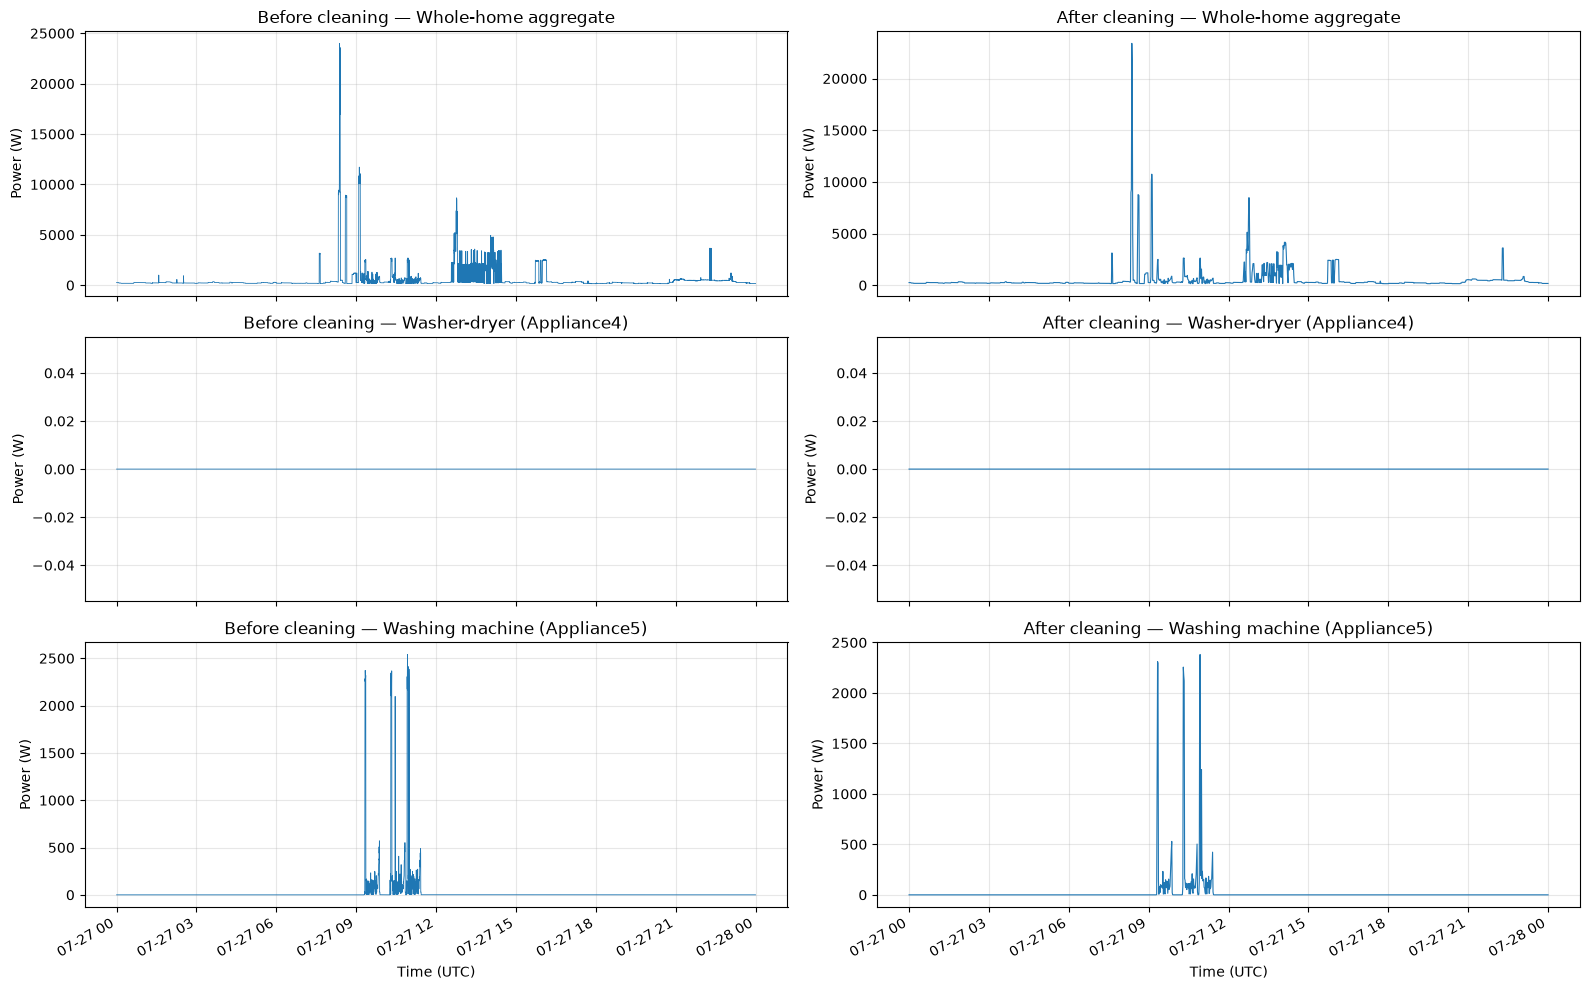

In [33]:

plot_start = pd.Timestamp("2014-07-27 00:00:00", tz="UTC")
plot_end = plot_start + pd.Timedelta(days=1)

before_plot = raw_before_dedup.copy()
before_plot["timestamp"] = pd.to_datetime(
    before_plot["Unix"], unit="s", utc=True
)
before_plot = before_plot.set_index("timestamp").sort_index()
before_plot = before_plot.loc[plot_start:plot_end]

after_plot = minute_clean.loc[plot_start:plot_end]

channels = [
    ("Aggregate", "Whole-home aggregate"),
    ("Appliance4", "Washer-dryer (Appliance4)"),
    ("Appliance5", "Washing machine (Appliance5)")
]

fig, axes = plt.subplots(3, 2, figsize=(16, 10), sharex=True)

for row, (col, label) in enumerate(channels):
    axes[row, 0].plot(
        before_plot.index,
        before_plot[col],
        linewidth=0.6
    )
    axes[row, 0].set_title(f"Before cleaning — {label}")
    axes[row, 0].set_ylabel("Power (W)")
    axes[row, 0].grid(True, alpha=0.3)

    axes[row, 1].plot(
        after_plot.index,
        after_plot[col],
        linewidth=0.8
    )
    axes[row, 1].set_title(f"After cleaning — {label}")
    axes[row, 1].set_ylabel("Power (W)")
    axes[row, 1].grid(True, alpha=0.3)

axes[-1, 0].set_xlabel("Time (UTC)")
axes[-1, 1].set_xlabel("Time (UTC)")

fig.autofmt_xdate()
plt.tight_layout()
plt.show()
